# 02 · Análise lexical

Visualizações **lexicais** (quais palavras dominam), lidas do CSV gerado pelo notebook 01. **Nenhum modelo é executado aqui.**

| Parâmetro | Significado |
|---|---|
| `MODELO`, `CONTEXTO` | escolhem o arquivo `dados/analise/tokens_{contexto}_{modelo}.csv` |
| `LEMAS` | `True`: conta **lemas**; `False`: conta **formas**. Se o modelo não lematiza, avisa e usa formas |
| `SEM_STOPWORDS` | `True`: os rankings (top-`TOP` e por classe) excluem stopwords. As tabelas de frequência são sempre gravadas com e sem stopwords |
| `TOP` | tamanho do ranking |
| `SEMENTE` | semente da nuvem de palavras |

Saídas em `saida/lexical/{modelo}_{contexto}/`. As stopwords vêm de uma lista única (`src/stopwords_pt.txt`) e são aplicadas à unidade contada (lema ou forma). Lemas de contrações ("em o") são separados nas componentes antes de contar.

## 0. Parâmetros

In [7]:
# ===================== PARÂMETROS (edite aqui) =====================
MODELO = "spacy"            # spacy | stanza | udpipe2 | trankit | bertimbau_ft
CONTEXTO = "poema"          # token | verso | poema
LEMAS = True                # True: conta lemas (se o modelo lematiza); False: conta formas
SEM_STOPWORDS = False        # exclui stopwords dos rankings (top-TOP e por classe)
TOP = 50                    # tamanho do ranking
SEMENTE = 42                # semente da nuvem de palavras
ARQUIVO_CSV = "dados/bruto/poemas.csv"   # só para métricas de texto (caracteres, sentenças)
FONTE_NUVEM = None          # ex.: "impact.ttf" (None = fonte padrão da nuvem)
# ===================================================================

In [8]:
import sys
from pathlib import Path

# raiz do projeto: a pasta que contém src/ (funciona rodando de projeto/ ou de projeto/notebooks/)
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import pandas as pd
from IPython.display import display

from src import carga, graficos, metricas
from src.stopwords import carregar_stopwords

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

carga.validar_parametros(MODELO, CONTEXTO)
tokens = carga.carregar_tokens(MODELO, CONTEXTO)         # para com mensagem se o notebook 01 não foi rodado
corpus = carga.carregar_corpus(carga.RAIZ / ARQUIVO_CSV)
stop = carregar_stopwords()
PASTA = carga.pasta_saida("lexical", MODELO, CONTEXTO)

usar_lemas = LEMAS and carga.tem_lema(tokens)
if LEMAS and not usar_lemas:
    print(f"AVISO: o modelo '{MODELO}' não forneceu lemas: contando formas.")
UNIDADE = "lemas" if usar_lemas else "formas"
SUF = f"_{UNIDADE}"
print(f"{len(tokens)} tokens em {tokens['poema_id'].nunique()} poemas | modelo={MODELO} contexto={CONTEXTO} | unidade: {UNIDADE}")
print("Saídas em:", PASTA)

9683 tokens em 111 poemas | modelo=spacy contexto=poema | unidade: lemas
Saídas em: C:\Users\Usuário\Desktop\Projeto-Portinari\frentes\analise_poemas\saida\lexical\spacy_poema


## 1. Métricas por poema

Sempre sobre as **formas**, independentemente de `LEMAS`: caracteres, tokens, tipos, comprimento médio da palavra, sentenças (separadas por `.`, `!`, `?`, `…`), tokens por sentença, tokens de conteúdo e proporção de palavras funcionais. A mediana é mais confiável que a média se houver poucos poemas muito longos.

In [9]:
por_poema = metricas.metricas_por_poema(tokens, corpus, stop)
por_poema.to_csv(PASTA / "metricas_por_poema.csv", index=False)
colunas = ["n_caracteres", "n_tokens", "n_tipos", "comp_medio_palavra", "n_sentencas", "tokens_por_sentenca",
           "n_tokens_conteudo", "prop_funcionais"]
display(por_poema[colunas].describe().T)
ordenado = por_poema.sort_values("n_tokens")
print("Poemas mais curtos / mais longos:")
display(pd.concat([ordenado[["poema_id", "n_tokens"]].head(3), ordenado[["poema_id", "n_tokens"]].tail(3)]))

,count,mean,std,min,25%,50%,75%,max
n_caracteres,111.000,514.991,232.042,187.000,369.500,472.000,600.500,1486.000
n_tokens,111.000,87.234,39.315,32.000,61.000,78.000,98.000,259.000
n_tipos,111.000,69.126,25.496,29.000,51.500,66.000,79.500,169.000
comp_medio_palavra,111.000,4.756,0.342,3.925,4.546,4.739,4.995,5.629
n_sentencas,111.000,9.099,4.786,1.000,6.000,9.000,11.000,36.000
tokens_por_sentenca,111.000,11.939,11.244,5.111,7.592,8.750,10.944,93.000
n_tokens_conteudo,111.000,43.937,19.640,15.000,30.500,39.000,52.000,125.000
prop_funcionais,111.000,0.494,0.055,0.300,0.458,0.500,0.528,0.616


Poemas mais curtos / mais longos:


,poema_id,n_tokens
55,poema_056,32
32,poema_033,33
96,poema_097,34
70,poema_071,186
86,poema_087,239
109,poema_110,259


## 2. Tabelas de frequência

`freq` = ocorrências totais; `df` = nº de poemas em que a unidade aparece. Gravadas com e sem stopwords.

In [10]:
unidades = metricas.tabela_de_unidades(tokens, usar_lemas)
freq_todas = metricas.tabela_frequencias(unidades)
freq_conteudo = metricas.tabela_frequencias(unidades, stop)
freq_todas.to_csv(PASTA / f"frequencias_todas{SUF}.csv", index=False)
freq_conteudo.to_csv(PASTA / f"frequencias_conteudo{SUF}.csv", index=False)
print(f"{len(freq_todas)} {UNIDADE} distintos; {len(freq_conteudo)} de conteúdo (sem stopwords)")

2222 lemas distintos; 2047 de conteúdo (sem stopwords)


## 3. Top-`TOP`

Cada barra mostra a **frequência total** (azul) e, sobreposto, o **nº de poemas** em que aparece (laranja). Com `SEM_STOPWORDS = True`, o ranking exclui as stopwords.

,palavra,freq,df
0,o,1497,111
1,de,681,108
2,e,363,105
3,em,333,100
4,a,160,80
5,ser,148,75
6,não,146,72
7,um,117,59
8,se,103,63
9,que,87,49


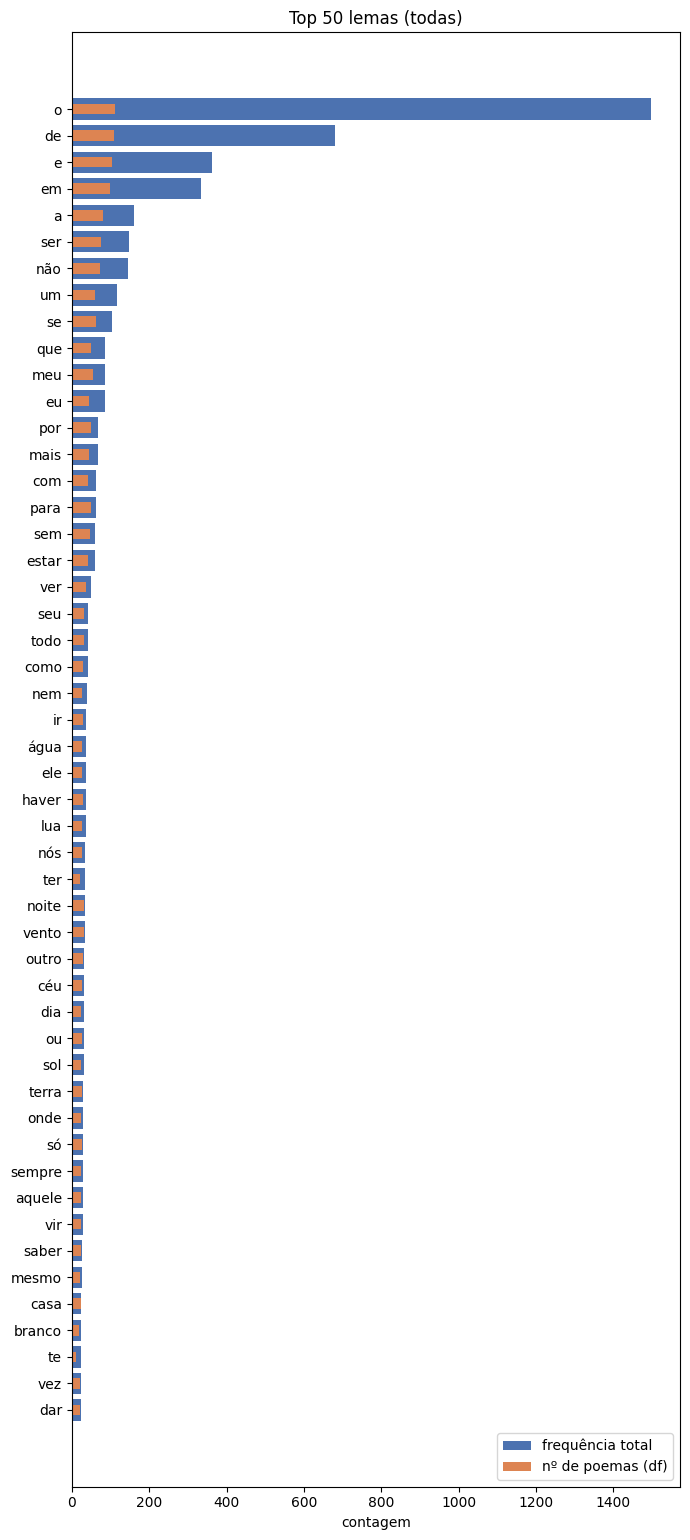

In [11]:
tab_top = freq_conteudo if SEM_STOPWORDS else freq_todas
rotulo = "de conteúdo" if SEM_STOPWORDS else "(todas)"
display(tab_top.head(TOP)[["palavra", "freq", "df"]])
graficos.barras_frequencia(tab_top, f"Top {TOP} {UNIDADE} {rotulo}", PASTA / f"top_palavras{SUF}.png", TOP)

## 4. Nuvem de palavras (palavras de conteúdo)

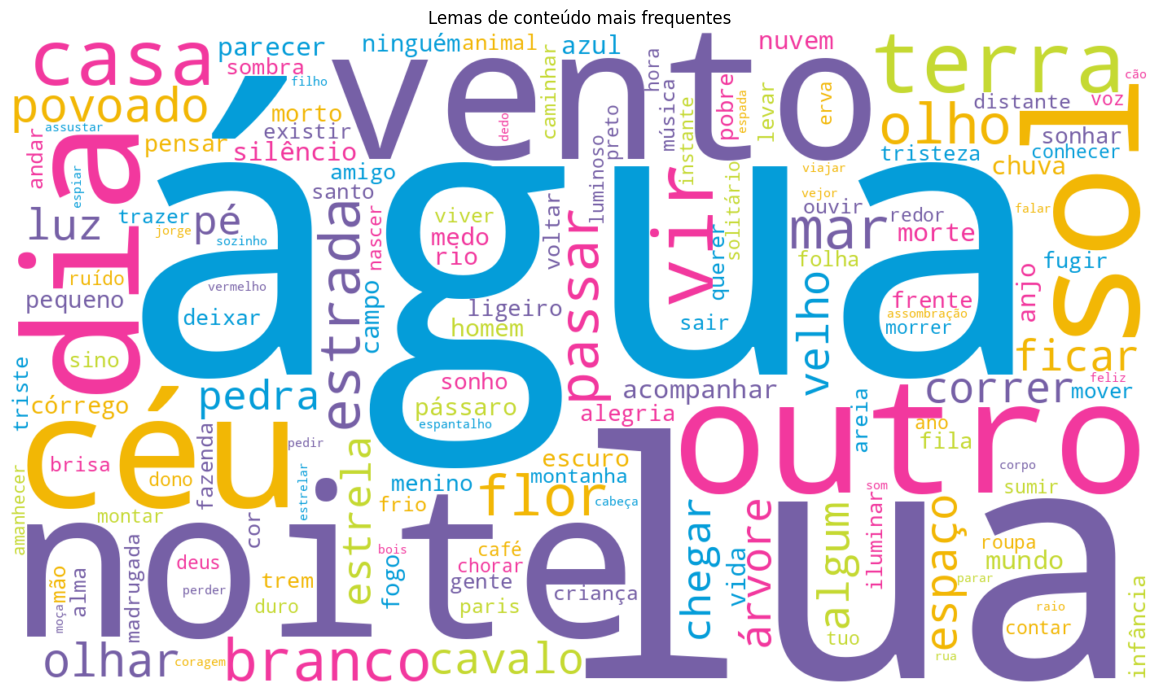

In [12]:
graficos.nuvem(freq_conteudo.head(150).set_index("palavra")["freq"], PASTA / f"nuvem{SUF}.png",
               semente=SEMENTE, fonte=FONTE_NUVEM, titulo=f"{UNIDADE.capitalize()} de conteúdo mais frequentes")

## 5. Top 10 por classe (NOUN, VERB, ADJ, ADV)

Disponível só com **lema e classe gramatical**. Em contrações ("dela" = "de" + "ela"), só a componente principal conta, na classe do token. Respeita `SEM_STOPWORDS`.


substantivos (NOUN)


,palavra,freq,df
0,água,37,27
1,lua,36,27
2,noite,34,31
3,vento,34,31
4,céu,32,27
5,dia,32,24
6,sol,31,25
7,terra,30,27
8,casa,25,23
9,vez,24,22


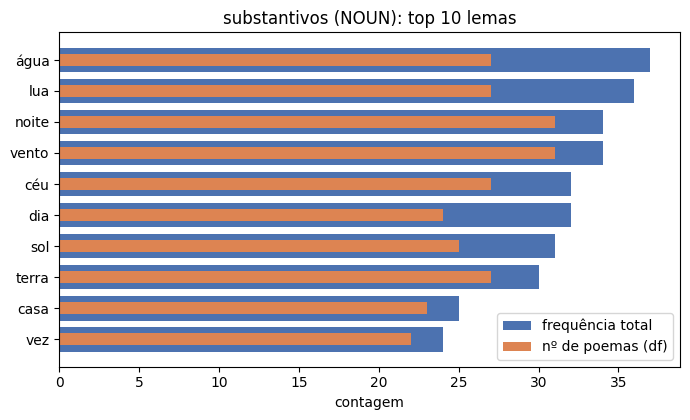


verbos (VERB)


,palavra,freq,df
0,ver,50,37
1,haver,36,30
2,vir,28,25
3,saber,27,23
4,ter,27,19
5,dar,24,21
6,passar,22,20
7,fazer,22,17
8,ficar,17,15
9,ir,17,14


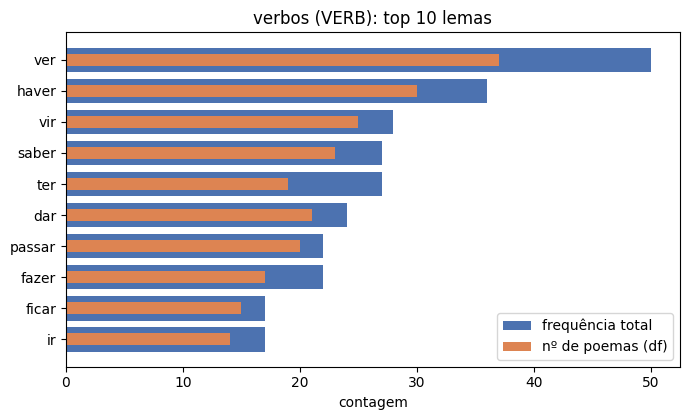


adjetivos (ADJ)


,palavra,freq,df
0,branco,23,19
1,velho,16,14
2,grande,12,12
3,pequeno,12,11
4,triste,9,8
5,ligeiro,8,8
6,azul,8,7
7,mesmo,8,6
8,bom,7,7
9,distante,7,7


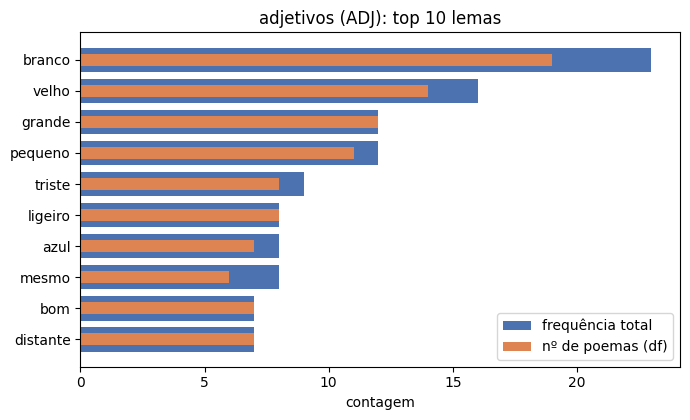


advérbios (ADV)


,palavra,freq,df
0,não,146,72
1,mais,65,45
2,só,29,26
3,sempre,28,24
4,já,18,18
5,lá,18,18
6,mesmo,18,18
7,ali,17,14
8,nunca,15,13
9,longe,14,13


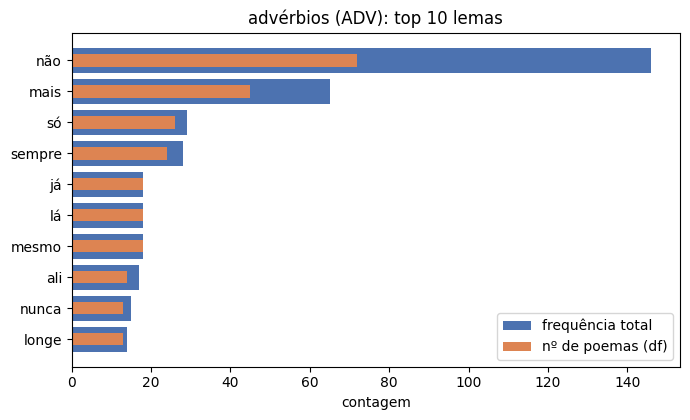

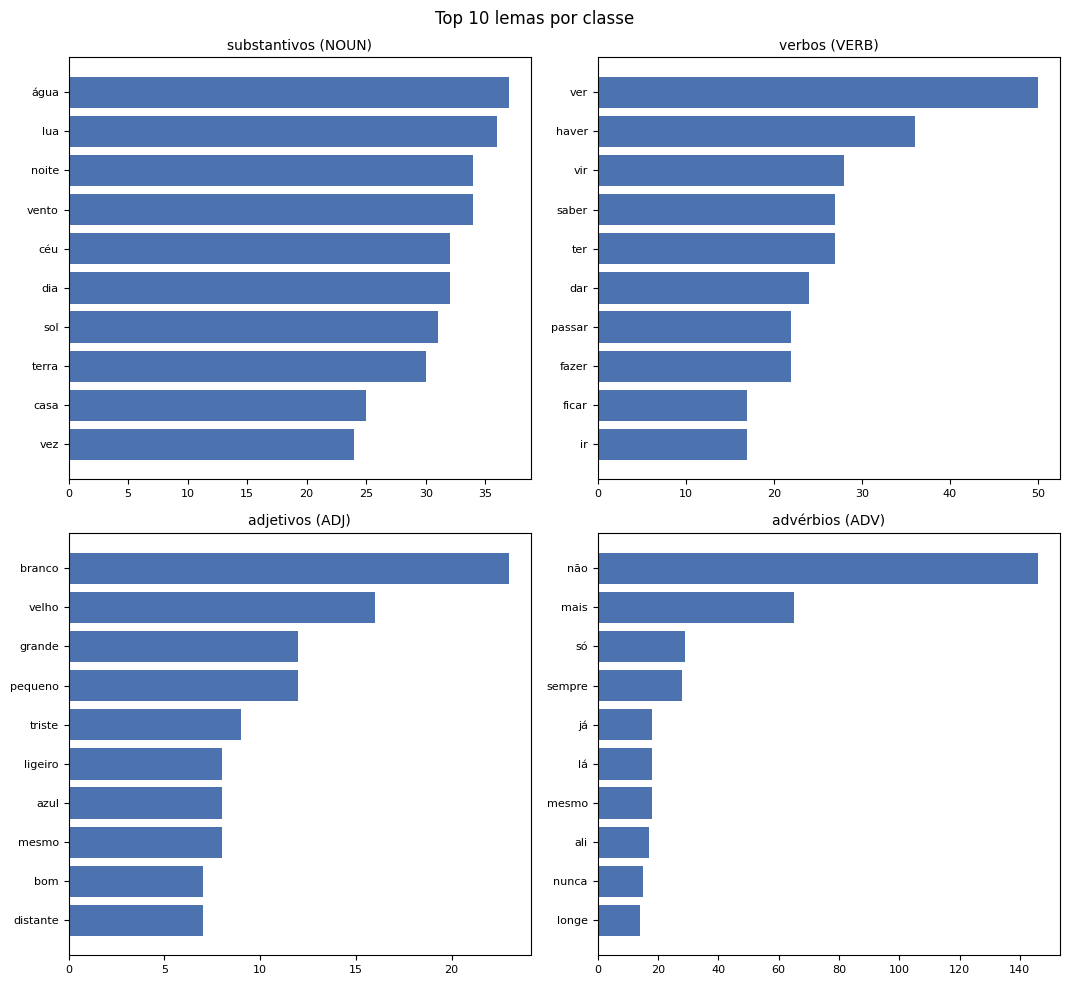

In [13]:
if not usar_lemas or not carga.tem_upos(tokens):
    print("AVISO: o top por classe exige lemas (LEMAS = True e modelo que lematiza) e classe gramatical: seção pulada.")
else:
    por_classe = metricas.frequencia_por_classe(unidades, metricas.CLASSES_PRINCIPAIS, stop if SEM_STOPWORDS else None)
    for classe, tab in por_classe.items():
        tab.to_csv(PASTA / f"freq_{classe}{SUF}.csv", index=False)
        print(f"\n{metricas.NOMES_CLASSES[classe]} ({classe})")
        display(tab.head(10)[["palavra", "freq", "df"]])
        graficos.barras_frequencia(tab, f"{metricas.NOMES_CLASSES[classe]} ({classe}): top 10 {UNIDADE}",
                                   PASTA / f"freq_{classe}{SUF}.png", 10)
    graficos.painel_classes(por_classe, metricas.NOMES_CLASSES, f"Top 10 {UNIDADE} por classe",
                            PASTA / f"classes_painel{SUF}.png")

## 7. Formas × lemas

Tamanho do vocabulário com formas e com lemas, e variação do posto dos `TOP` lemas de conteúdo mais frequentes (`variacao_do_posto > 0`: o lema sobe no ranking em relação à forma de mesma grafia). Exige modelo que lematiza.

,conjunto,tipos_formas,tipos_lemas,reducao_do_vocabulario
0,todas as palavras,2927,2222,0.241
1,palavras de conteúdo,2658,2047,0.230


,lema,freq_lema,df_lema,rank_lema,freq_forma_igual,rank_forma_igual,variacao_do_posto
0,água,38,27,1,19.000,15.000,14.000
1,lua,36,27,2,36.000,1.000,-1.000
2,noite,34,31,3,22.000,7.000,4.000
3,vento,34,31,4,28.000,4.000,0.000
4,outro,32,29,5,13.000,22.000,17.000
5,céu,32,27,6,32.000,2.000,-4.000
6,dia,32,24,7,19.000,14.000,7.000
7,sol,31,25,8,31.000,3.000,-5.000
8,terra,30,27,9,22.000,6.000,-3.000
9,vir,28,25,10,NaN,NaN,NaN


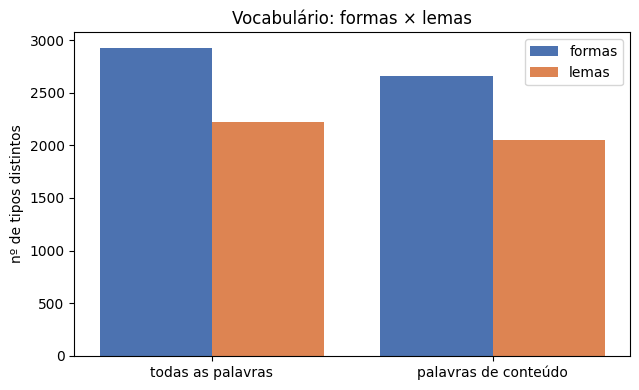

In [14]:
if not carga.tem_lema(tokens):
    print("AVISO: o modelo não forneceu lemas: comparação formas × lemas pulada.")
else:
    resumo_vocab, ranking = metricas.comparar_formas_lemas(tokens, stop, TOP)
    resumo_vocab.to_csv(PASTA / "formas_vs_lemas_vocabulario.csv", index=False)
    ranking.to_csv(PASTA / "formas_vs_lemas_ranking.csv", index=False)
    display(resumo_vocab)
    display(ranking.head(20))
    graficos.comparacao_vocabulario(resumo_vocab, PASTA / "formas_vs_lemas_vocabulario.png")

## Observações

- **Os lemas dependem do modelo e da convenção**; o nome do modelo consta no nome da pasta de saída e em `registro.csv`.
- **Palavras que o lematizador deixa como estão** (por exemplo, classificadas como nome próprio) não se juntam às suas variantes; veja a auditoria no notebook 01.
- Um modelo sem lema (`bertimbau_ft`) cai para formas, com aviso.

,upos,n,prop
7,NOUN,2546,0.263
13,VERB,1696,0.175
1,ADP,1396,0.144
5,DET,1264,0.131
2,ADV,625,0.065
0,ADJ,562,0.058
9,PRON,484,0.050
4,CCONJ,442,0.046
3,AUX,241,0.025
10,PROPN,191,0.020


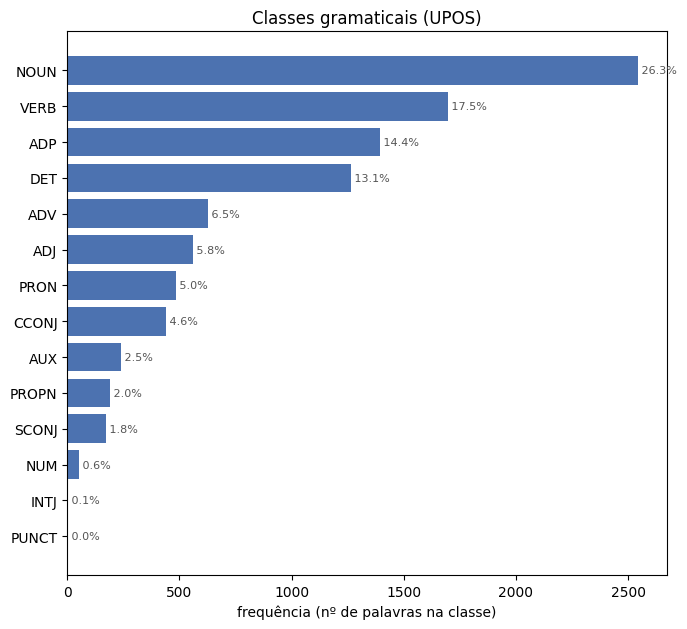

In [15]:

# Frequência total por classe gramatical (UPOS)

# Usar as formas ou os lemas conforme os parâmetros do notebook
coluna_unidade = "lema" if usar_lemas else "forma"

# Selecionar tokens com classe gramatical identificada
dados_upos = tokens.dropna(subset=["upos"]).copy()
dados_upos = dados_upos[dados_upos["upos"].astype(str).str.strip() != ""]

# Respeitar SEM_STOPWORDS
if SEM_STOPWORDS:
    dados_upos = dados_upos[
        ~dados_upos[coluna_unidade].isin(stop)
    ]

# Somar as ocorrências de cada classe gramatical
freq_upos = (
    dados_upos.groupby("upos")
    .size()
    .rename("n")
    .reset_index()
    .sort_values("n", ascending=False)
)

# Calcular a proporção de cada classe
freq_upos["prop"] = freq_upos["n"] / freq_upos["n"].sum()

# Exibir a tabela de frequências
display(freq_upos)

# Salvar a tabela
freq_upos.to_csv(
    PASTA / f"frequencia_upos{SUF}.csv",
    index=False
)

# Gerar o gráfico usando a função existente em src/graficos.py
graficos.barras_upos(
    freq_upos,
    metricas.NOMES_CLASSES,
    caminho=PASTA / f"frequencia_upos{SUF}.png"
)
